# SmartLocator floor detection: threshold rules vs a learned model

**Mini prototype experiment** on my own earlier test readings (BME280 pressure, one building, two test sessions on different days).
Goal: check whether a model that *learns* its cut-offs from labelled data does better than my hand-set threshold rules.

- Feature: pressure change from the floor-1 baseline (`delta_hPa`)
- Label: the floor I was physically on (readings on the stairs are left out)
- Fair test: train on one session, test on the other session
- BLE proximity is not part of this experiment because I did not record data for it

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

df = pd.read_csv("pressure_labelled.csv")
data = df[df["use_for_ml"]].copy()
data["floor"] = data["true_floor"].astype(int)

print(f"{len(df)} readings in total")
print(f"{int(df['moving'].sum())} moving-on-stairs readings and {int(df['typo_excluded'].sum())} mistyped readings left out")
print(f"{len(data)} readings used")
data.groupby(["test", "floor"]).size().unstack("test").rename_axis("floor (0 = ground)")

1152 readings in total
91 moving-on-stairs readings and 2 mistyped readings left out
1059 readings used


test,A,B
floor (0 = ground),,
0,40,20
1,62,95
2,85,138
3,281,112
4,185,41


## 1. What the data looks like
Each dot is one reading. Higher floors have a bigger pressure drop below the floor-1 baseline.
Dashed lines are my hand-set cut-offs (the chart shows the pressure drop, so the -0.20 line is the "same floor" edge on the other side). The two test days line up, even though the raw pressure was different between the days.

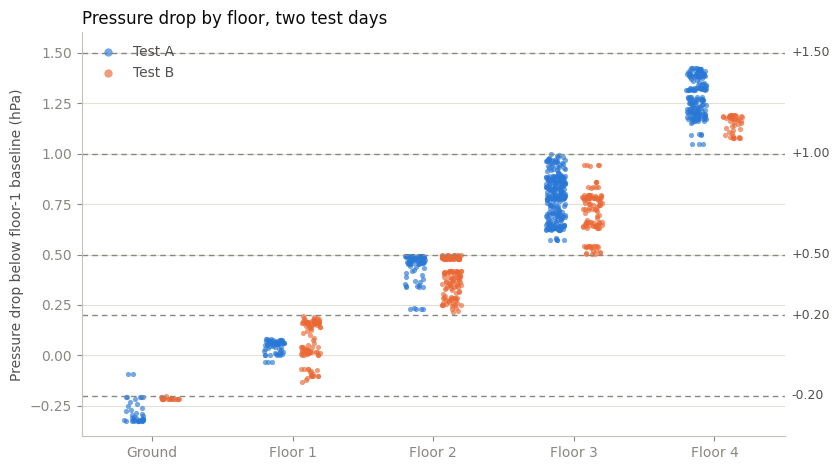

In [2]:
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
FLOOR_NAMES = ["Ground", "Floor 1", "Floor 2", "Floor 3", "Floor 4"]

def tidy_axes(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=10)
    ax.set_axisbelow(True)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
rng = np.random.default_rng(0)
for t, color, dx in [("A", BLUE, -0.13), ("B", ORANGE, 0.13)]:
    s = data[data["test"] == t]
    ax.scatter(s["floor"] + dx + rng.uniform(-0.07, 0.07, len(s)), -s["delta_hPa"],
               s=14, color=color, alpha=0.65, linewidths=0, label=f"Test {t}")
for y, lab in [(-0.20, "-0.20"), (0.20, "+0.20"), (0.50, "+0.50"), (1.00, "+1.00"), (1.50, "+1.50")]:
    ax.axhline(y, color=MUTED, lw=1, ls=(0, (4, 3)))
    ax.text(4.55, y, lab, va="center", ha="left", color=INK2, fontsize=9)
ax.set_xticks(range(5))
ax.set_xticklabels(FLOOR_NAMES)
ax.set_xlim(-0.5, 4.5)
ax.set_ylim(-0.4, 1.6)
ax.set_ylabel("Pressure drop below floor-1 baseline (hPa)", color=INK2, fontsize=10)
ax.yaxis.grid(True, color=GRID, lw=0.8)
tidy_axes(ax)
ax.legend(frameon=False, loc="upper left", fontsize=10, markerscale=1.6, labelcolor=INK2)
ax.set_title("Pressure drop by floor, two test days", loc="left", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig("delta_by_floor.png", dpi=160, facecolor="#fcfcfb")
plt.show()

## 2. My threshold rules (the baseline)
The user picks any floor as the baseline, and the app measures `delta = pressure now - baseline pressure`.
My bands on |delta| (hPa): below 0.20 = same floor, 0.20-0.50 = 1 floor, 0.50-1.00 = 2 floors, 1.00-1.50 = 3 floors, above 1.50 = 4 floors.
These are the same bands as the firmware's `detectFloor()` (a reading exactly on 0.50, 1.00 or 1.50 goes into the smaller band, like `<=` in the firmware).
Rising pressure means going down, falling pressure means going up. The result is kept between ground and floor 4.

In [3]:
BASE_FLOOR = 1  # both tests used floor 1 as the baseline floor

def threshold_floor(delta):
    a = abs(delta)
    # same as the firmware detectFloor(): ad < 0.20 -> 0, ad <= 0.50 -> 1, ad <= 1.00 -> 2, ad <= 1.50 -> 3, else 4
    n = 0 if a < 0.20 else 1 if a <= 0.50 else 2 if a <= 1.00 else 3 if a <= 1.50 else 4
    return int(np.clip(BASE_FLOOR - np.sign(delta) * n, 0, 4))

## 3. Train on one test day, test on the other
Only one input (`delta_hPa`), so the tree is simply learning its own cut-offs.
`max_leaf_nodes=5` gives five zones (five floors), the same as my rules, so the cut-offs can be compared directly.

In [4]:
def run(train_t, test_t):
    tr, te = data[data["test"] == train_t], data[data["test"] == test_t]
    X_tr, X_te = tr[["delta_hPa"]], te[["delta_hPa"]]
    tree = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0).fit(X_tr, tr["floor"])
    forest = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=0).fit(X_tr, tr["floor"])
    preds = {
        "My threshold rules": te["delta_hPa"].map(threshold_floor),
        "Decision tree (learned cut-offs)": pd.Series(tree.predict(X_te), index=te.index),
        "Random forest": pd.Series(forest.predict(X_te), index=te.index),
    }
    return te, preds, tree

results = {}
store = {}
for tr_t, te_t in [("A", "B"), ("B", "A")]:
    te, preds, tree = run(tr_t, te_t)
    store[(tr_t, te_t)] = (te, preds, tree)
    results[f"Train {tr_t}, test {te_t} ({len(te)} readings)"] = {
        name: accuracy_score(te["floor"], p) for name, p in preds.items()}

table = pd.DataFrame(results)
table.map(lambda v: f"{v:.1%}")

,"Train A, test B (406 readings)","Train B, test A (653 readings)"
My threshold rules,100.0%,99.7%
Decision tree (learned cut-offs),85.7%,99.7%
Random forest,85.7%,99.7%


## 4. Where does each method get it wrong? (train A, test B)
Rows are the true floor, columns are the predicted floor. The diagonal is correct.

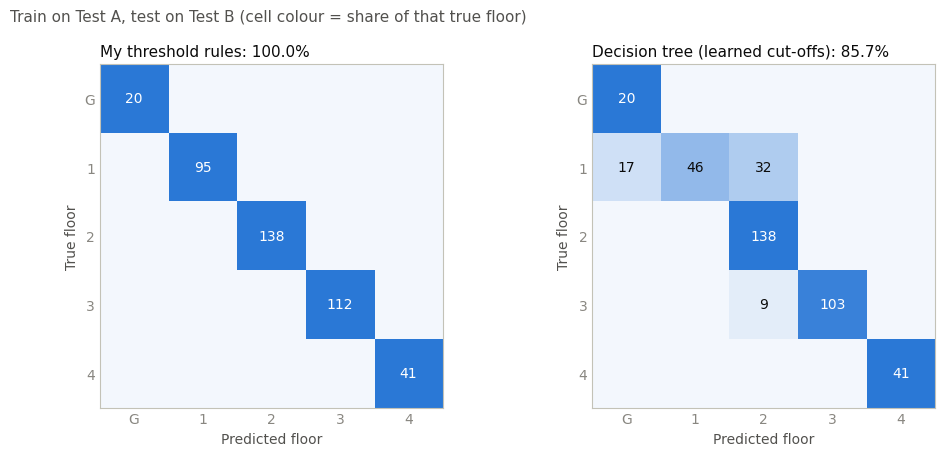

In [5]:
te, preds, tree_A = store[("A", "B")]
show = [("My threshold rules", "My threshold rules"),
        ("Decision tree (learned cut-offs)", "Decision tree (learned cut-offs)")]
cmap = LinearSegmentedColormap.from_list("blue_seq", ["#f3f7fd", "#2a78d6"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, (key, title) in zip(axes, show):
    cm = confusion_matrix(te["floor"], preds[key], labels=range(5))
    frac = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(frac, cmap=cmap, vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10,
                        color="white" if frac[i, j] > 0.55 else INK)
    ax.set_xticks(range(5)); ax.set_yticks(range(5))
    ax.set_xticklabels(["G", "1", "2", "3", "4"]); ax.set_yticklabels(["G", "1", "2", "3", "4"])
    ax.set_xlabel("Predicted floor", color=INK2, fontsize=10)
    ax.set_ylabel("True floor", color=INK2, fontsize=10)
    acc = accuracy_score(te["floor"], preds[key])
    ax.set_title(f"{title}: {acc:.1%}", loc="left", color=INK, fontsize=11)
    for side in ax.spines.values():
        side.set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=10, length=0)
fig.suptitle("Train on Test A, test on Test B (cell colour = share of that true floor)", x=0.01, ha="left", fontsize=11, color=INK2)
fig.tight_layout()
fig.savefig("confusion_matrices.png", dpi=160, facecolor="#fcfcfb")
plt.show()

In [6]:
cut = lambda t: sorted(round(float(x), 3) for x in t.tree_.threshold[t.tree_.feature >= 0])
print("Hand-set cut-offs on delta_hPa :", [-1.00, -0.50, -0.20, 0.20])
print("Tree cut-offs learned from A   :", cut(tree_A))
print("Tree cut-offs learned from B   :", cut(store[("B", "A")][2]))
print()
for key in ["My threshold rules", "Decision tree (learned cut-offs)"]:
    wrong = te[preds[key] != te["floor"]]
    print(f"{key}: {len(wrong)} wrong out of {len(te)} (test B)")
    print(wrong.groupby(["segment", "segment_label"]).size().rename("wrong readings").to_string())
    print()

Hand-set cut-offs on delta_hPa : [-1.0, -0.5, -0.2, 0.2]
Tree cut-offs learned from A   : [-1.022, -0.533, -0.156, 0.061]
Tree cut-offs learned from B   : [-1.01, -0.5, -0.206, 0.167]

My threshold rules: 0 wrong out of 406 (test B)
Series([], )

Decision tree (learned cut-offs): 58 wrong out of 406 (test B)
segment  segment_label  
11       To floor 3 back     9
15       To floor 1 back    39
17       To floor 1 back    10



In [7]:
f1 = data[data["floor"] == 1].groupby("test")["delta_hPa"].agg(["min", "max", "count"]).round(3)
f1.rename(columns={"min": "lowest delta", "max": "highest delta", "count": "readings"})

,lowest delta,highest delta,readings
test,,,
A,-0.081,0.032,62
B,-0.197,0.131,95


## What I found
- **My rules held up.** They scored 100% (test B, 0 wrong out of 406) and 99.7% (test A, 2 wrong out of 653; both are the same reading near the start of the "to ground" stay, so that label may be rough). The largest change in the data is about 1.42 hPa, so the "above 1.50 = 4 floors" band was never needed here.
- **The model mostly rediscovered my cut-offs.** For the upper floors the learned cut-offs landed within about 0.03 hPa of my -0.50 and -1.00 lines.
- **The model did not beat my rules.** Trained on test A it scored 85.7% on test B. In test A, floor-1 readings only covered a narrow range (table above), so the tree learned zones that were too tight. In test B the floor-1 pressure drifted over a wider range, and a fixed cut-off learned from one day broke. My +/-0.20 margin was safer.
- So the useful result is not "ML wins". It is that a learned model needs data from more days and weather, and that pressure drift is the real problem to solve.

## Limitations and next steps
- Small data: one building, one device, 6 + 11 stays. Readings in a row are very similar, so the real number of independent tests is small. Treat the numbers as a prototype result, not proof.
- If my cut-offs were chosen by looking at readings like these, their score is optimistic and not a clean "untrained" baseline.
- Both tests used floor 1 as the baseline, so the model only learned "distance from floor 1". My real system lets the user pick any floor as the baseline, so this needs data from other baseline floors.
- The logged values are the firmware's filtered pressure (median, moving average, EMA). The firmware snaps the filter to the raw reading when it jumps by more than 0.10 hPa, which is the likely source of the sudden ~0.10 hPa steps seen in the data.
- Only one feature (`delta_hPa`). With one feature a tree is just learning cut-offs.
- Some labels may be rough: in segments 11, 15 and 17 the pressure keeps changing by about a floor's worth in rows that are not marked as moving.
- Next steps: log new data with the floor labelled as I go, add features such as the recent rate of change, and compare the time taken to show the correct floor, not only accuracy.